# Blunder model: can we predict blunders without an engine?

Can we predict whether the player about to move will blunder, using only engine-free
features that the live lane can compute? This notebook trains on the feature table built by
`ingest/build_features.py`, which replays every parsed game through the shared
`features.compute_features`, the same code the live consumer will run.

Prerequisites (from the repo root):

```powershell
uv run python -m ingest.parse_archive data\raw\lichess_db_standard_rated_2026-09.part.pgn.zst --games 60000
uv run python -m ingest.load_openings
uv run python -m ingest.build_features
uv run python -m ingest.build_features --no-interpolated --out data\parquet\features_named
```

**Done when:** the model clearly beats the clock-only baseline on PR-AUC.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score, brier_score_loss, precision_recall_curve, roc_auc_score

from features import BLUNDER_THRESHOLD, FEATURES, PHASE_2B, is_scored

BLUE, ORANGE, GREY, INK = "#2a78d6", "#eb6834", "#8a8984", "#52514e"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "figure.dpi": 110,
})
pd.set_option("display.float_format", "{:.4f}".format)

## 1. Load and filter

Bots and UltraBullet are dropped (`is_scored`). The label is a win-probability drop of at
least `BLUNDER_THRESHOLD` (0.15). Booleans become 0/1 and `eco_family` a categorical, which
`HistGradientBoostingClassifier` handles natively. Missing values (`prev_time_spent` on a
player's first move, `eco_family` before any book position) stay NaN.

In [2]:
OPENING = ["in_book", "plies_out_of_book", "eco_family"]


def load(path: Path) -> pd.DataFrame:
    df = pd.read_parquet(path)
    keep = np.array([is_scored(w, b, s) for w, b, s in zip(df.white_title, df.black_title, df.speed)])
    print(f"{path.name}: {len(df):,} rows, dropped {(~keep).sum():,} (bots, UltraBullet)")
    df = df[keep].copy()
    df["blunder"] = df.wp_drop >= BLUNDER_THRESHOLD
    df[["in_check", "in_book"]] = df[["in_check", "in_book"]].astype(int)
    df["eco_family"] = pd.Categorical(df.eco_family, categories=list("ABCDE"))
    return df


df = load(ROOT / "data/parquet/features")
print(f"{df.game_id.nunique():,} games, {len(df):,} moves, blunder rate {df.blunder.mean():.2%}")

features: 3,869,810 rows, dropped 34,434 (bots, UltraBullet)


59,366 games, 3,835,376 moves, blunder rate 6.90%


## 2. Where blunders happen

Blunder rate against a few single features, before any model. Each panel is one feature cut
into bands.

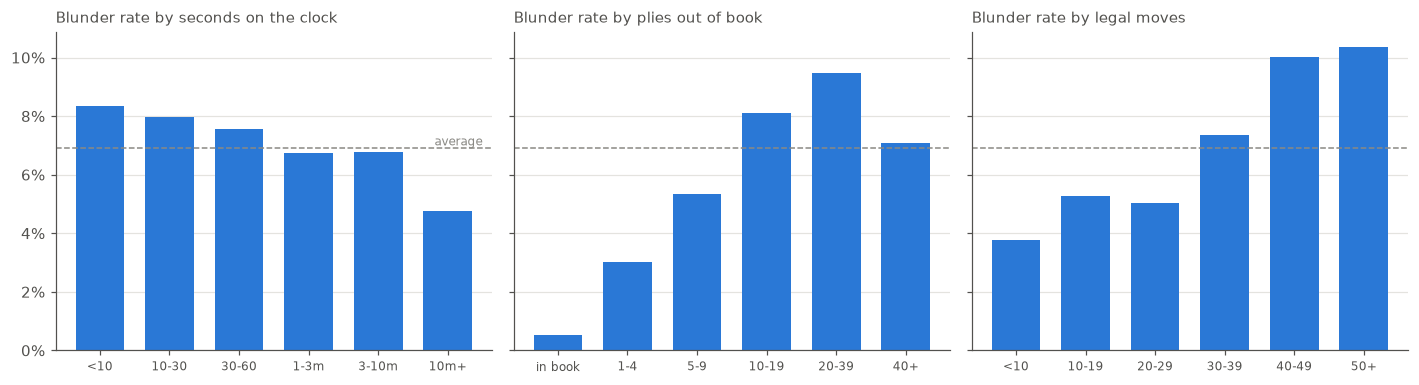

In [3]:
bands = {
    "seconds on the clock": pd.cut(df.clock, [0, 10, 30, 60, 180, 600, np.inf], right=False,
                                   labels=["<10", "10-30", "30-60", "1-3m", "3-10m", "10m+"]),
    "plies out of book": pd.cut(df.plies_out_of_book, [0, 1, 5, 10, 20, 40, np.inf], right=False,
                                labels=["in book", "1-4", "5-9", "10-19", "20-39", "40+"]),
    "legal moves": pd.cut(df.legal_moves, [0, 10, 20, 30, 40, 50, np.inf], right=False,
                          labels=["<10", "10-19", "20-29", "30-39", "40-49", "50+"]),
}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (name, band) in zip(axes, bands.items()):
    rate = df.blunder.groupby(band, observed=True).mean()
    ax.bar(rate.index.astype(str), rate.values, color=BLUE, width=0.7)
    ax.axhline(df.blunder.mean(), color=GREY, linestyle="--", linewidth=1)
    ax.set_title(f"Blunder rate by {name}", fontsize=10, color=INK, loc="left")
    ax.tick_params(axis="x", labelsize=8)
    ax.grid(axis="x", visible=False)
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
axes[0].text(len(rate) - 0.5, df.blunder.mean(), " average", va="bottom", ha="right", fontsize=8, color=GREY)
plt.tight_layout()

In [4]:
df.groupby("speed").agg(moves=("blunder", "size"), blunder_rate=("blunder", "mean")).sort_values("moves", ascending=False)

,moves,blunder_rate
speed,,
blitz,1778733,0.0663
rapid,1206860,0.0694
bullet,783099,0.0749
classical,66684,0.0623


## 3. Time-based split

The parser wrote parts of 2,000 games in archive order, so the last six parts (about 12,000
games, 20%) are the newest games and form the test set. This mirrors the DAG, which tests each
retrain on the newest batch. Splitting by game also keeps moves of one game on one side.

In [5]:
TEST_PARTS = 6
first_test = df.part.max() + 1 - TEST_PARTS
is_test = df.part >= first_test
train, test = df[~is_test], df[is_test]
print(f"train: {train.game_id.nunique():,} games, {len(train):,} moves, blunder rate {train.blunder.mean():.2%}")
print(f"test:  {test.game_id.nunique():,} games, {len(test):,} moves, blunder rate {test.blunder.mean():.2%}")

train: 47,512 games, 3,075,138 moves, blunder rate 6.90%
test:  11,854 games, 760,238 moves, blunder rate 6.89%


## 4. Baselines and model

- **Base rate**: predict the training blunder rate for every move. Its PR-AUC equals the
  blunder rate.
- **Clock only**: the same classifier on seconds remaining alone.
- **Model**: all 26 features, with and without `class_weight="balanced"`.

PR-AUC is the headline metric (blunders are 7% of moves, so accuracy says nothing). Brier score
and the calibration plot check whether the probabilities can be shown as they are.

In [6]:
PARAMS = dict(max_iter=500, early_stopping=True, random_state=0)


def fit(cols, train=train, **kw):
    model = HistGradientBoostingClassifier(**PARAMS, **kw).fit(train[cols], train.blunder)
    return model


def metrics(p, y=test.blunder):
    return {"PR-AUC": average_precision_score(y, p), "ROC-AUC": roc_auc_score(y, p),
            "Brier": brier_score_loss(y, p), "mean p": p.mean()}


preds = {"base rate": np.full(len(test), train.blunder.mean())}
clock_model = fit(["clock"])
preds["clock only"] = clock_model.predict_proba(test[["clock"]])[:, 1]
model = fit(FEATURES)
preds["model"] = model.predict_proba(test[FEATURES])[:, 1]
weighted = fit(FEATURES, class_weight="balanced")
preds["model, class-weighted"] = weighted.predict_proba(test[FEATURES])[:, 1]

results = pd.DataFrame({name: metrics(p) for name, p in preds.items()}).T
results["lift over clock"] = results["PR-AUC"] / results.loc["clock only", "PR-AUC"]
print(f"model stopped after {model.n_iter_} iterations")
results

model stopped after 217 iterations


,PR-AUC,ROC-AUC,Brier,mean p,lift over clock
base rate,0.0689,0.5000,0.0642,0.0690,0.8036
clock only,0.0858,0.5914,0.0636,0.0685,1.0000
model,0.1768,0.7686,0.0602,0.0684,2.0612
"model, class-weighted",0.1779,0.7700,0.2029,0.3930,2.0749


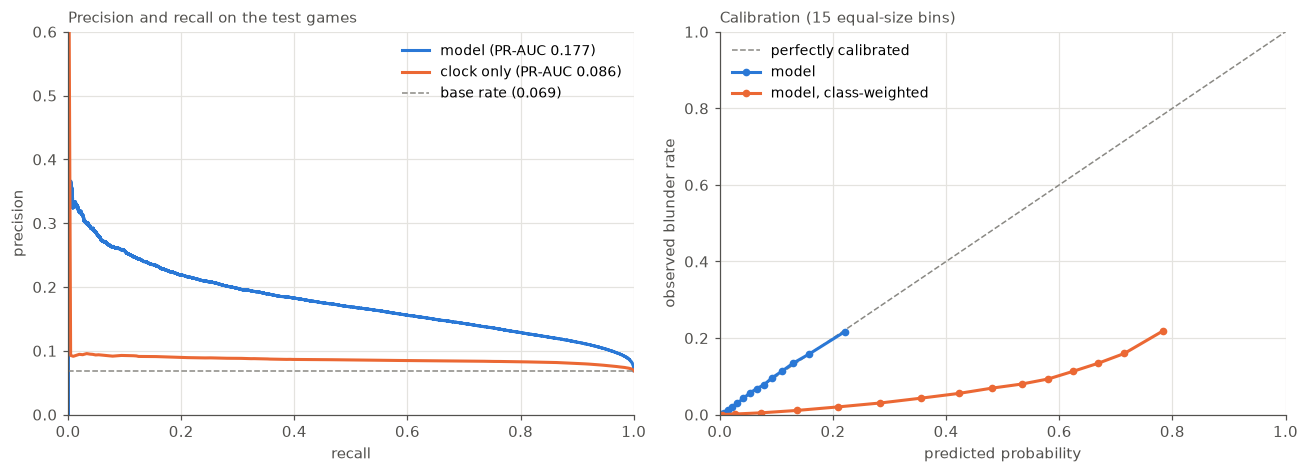

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4))

for name, color in [("model", BLUE), ("clock only", ORANGE)]:
    precision, recall, _ = precision_recall_curve(test.blunder, preds[name])
    ax1.plot(recall, precision, color=color, label=f"{name} (PR-AUC {results.loc[name, 'PR-AUC']:.3f})")
ax1.axhline(test.blunder.mean(), color=GREY, linestyle="--", linewidth=1, label=f"base rate ({test.blunder.mean():.3f})")
ax1.set(xlabel="recall", ylabel="precision", xlim=(0, 1), ylim=(0, 0.6))
ax1.set_title("Precision and recall on the test games", fontsize=10, color=INK, loc="left")
ax1.legend(frameon=False, fontsize=9)

ax2.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1, label="perfectly calibrated")
for name, color in [("model", BLUE), ("model, class-weighted", ORANGE)]:
    frac, mean_p = calibration_curve(test.blunder, preds[name], n_bins=15, strategy="quantile")
    ax2.plot(mean_p, frac, color=color, marker="o", markersize=4, label=name)
ax2.set(xlabel="predicted probability", ylabel="observed blunder rate", xlim=(0, 1), ylim=(0, 1))
ax2.set_title("Calibration (15 equal-size bins)", fontsize=10, color=INK, loc="left")
ax2.legend(frameon=False, fontsize=9)
plt.tight_layout()

## 5. Do the opening-book features help?

The plan flagged this as a risk: most games leave the book by ply 11. Two checks against the
full model: drop the three opening features, and rebuild them from named openings only
(without `eco_interpolated.json`).

In [8]:
no_opening = [f for f in FEATURES if f not in OPENING]
ablation = {"all features": preds["model"],
            "no opening features": fit(no_opening).predict_proba(test[no_opening])[:, 1]}

named = load(ROOT / "data/parquet/features_named")
named_train, named_test = named[named.part < first_test], named[named.part >= first_test]
ablation["named openings only"] = fit(FEATURES, train=named_train).predict_proba(named_test[FEATURES])[:, 1]

pd.DataFrame({name: metrics(p) for name, p in ablation.items()}).T[["PR-AUC", "ROC-AUC", "Brier"]]

features_named: 3,869,810 rows, dropped 34,434 (bots, UltraBullet)


,PR-AUC,ROC-AUC,Brier
all features,0.1768,0.7686,0.0602
no opening features,0.1757,0.7674,0.0602
named openings only,0.1768,0.7686,0.0602


## 6. Phase 2b: threats and game history

Phase 2b added two engine-free groups to the original 15 features:

- **Threats** (8): own pieces attacked, en prise (attacked and undefended, or attacked by a cheaper
  piece) and the value of the most valuable one, the same for the opponent's pieces (what the mover
  could win), pinned pieces, attacked squares around the king, captures and checks available. A proxy
  for "there is something to answer here and the right move is hard to find".
- **History** (3): material change over the last 4 plies, material below the mover's best point in the
  game, average time over the mover's last 3 moves. A proxy for "has this game already gone wrong".

In [9]:
original = [f for f in FEATURES if f not in PHASE_2B]
threats, history = PHASE_2B[:8], PHASE_2B[8:]
groups = {"phase 2 (15 features)": original, "+ threats": original + threats,
          "+ history": original + history, "all 26 features": FEATURES}
group_preds = {name: fit(cols).predict_proba(test[cols])[:, 1] for name, cols in groups.items()}
pd.DataFrame({name: metrics(p) for name, p in group_preds.items()}).T[["PR-AUC", "ROC-AUC", "Brier"]]

,PR-AUC,ROC-AUC,Brier
phase 2 (15 features),0.1560,0.7429,0.0611
+ threats,0.1743,0.7664,0.0603
+ history,0.1572,0.7450,0.0610
all 26 features,0.1768,0.7686,0.0602


## 7. Which features carry the model

Permutation importance on 200,000 test moves: how much PR-AUC drops when one feature is
shuffled.

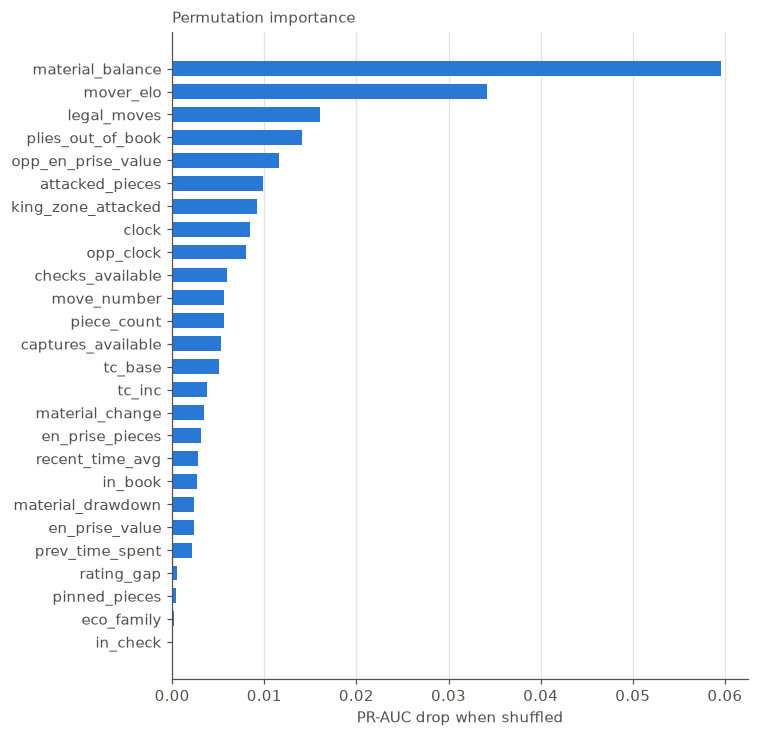

In [10]:
sample = test.sample(200_000, random_state=0)
imp = permutation_importance(model, sample[FEATURES], sample.blunder, scoring="average_precision",
                             n_repeats=3, random_state=0, n_jobs=-1)
importance = pd.Series(imp.importances_mean, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(7, 6.8))
ax.barh(importance.index, importance.values, color=BLUE, height=0.65)
ax.set_xlabel("PR-AUC drop when shuffled")
ax.set_title("Permutation importance", fontsize=10, color=INK, loc="left")
ax.grid(axis="y", visible=False)
plt.tight_layout()

## 8. What a flag means in practice

If the dashboard highlights the riskiest moves, how often is it right? Precision and recall
when flagging the top 1%, 5% and 10% of moves by predicted probability, plus lift over the base
rate.

In [11]:
rows = []
for share in [0.01, 0.05, 0.10]:
    cut = np.quantile(preds["model"], 1 - share)
    flagged = preds["model"] >= cut
    rows.append({"flag top": f"{share:.0%}", "threshold p": cut,
                 "precision": test.blunder[flagged].mean(),
                 "recall": test.blunder[flagged].sum() / test.blunder.sum(),
                 "lift": test.blunder[flagged].mean() / test.blunder.mean()})
pd.DataFrame(rows).set_index("flag top")

,threshold p,precision,recall,lift
flag top,,,,
1%,0.2576,0.2916,0.0423,4.2310
5%,0.1909,0.2286,0.1659,3.3175
10%,0.1573,0.1997,0.2898,2.8982


## 9. Sanity checks

Against Lichess's own annotations (`lichess_nag`, never used as a label or feature): moves
Lichess marked `??` should get the highest predicted probabilities. And PR-AUC per speed, since
the dashboard shows one TV channel at a time.

In [12]:
nag = test.lichess_nag.fillna("none")
pd.DataFrame({"moves": nag.value_counts(), "mean predicted p": pd.Series(preds["model"], index=test.index).groupby(nag).mean(),
              "blunder rate": test.blunder.groupby(nag).mean()}).loc[["none", "?!", "?", "??"]]

,moves,mean predicted p,blunder rate
lichess_nag,,,
none,601063,0.0598,0.0001
?!,46001,0.0765,0.0000
?,73979,0.1029,0.2635
??,39195,0.1258,0.8377


In [13]:
p_model = pd.Series(preds["model"], index=test.index)
pd.DataFrame({
    speed: {"moves": len(g), "blunder rate": g.blunder.mean(),
            "PR-AUC model": average_precision_score(g.blunder, p_model[g.index]),
            "PR-AUC clock only": average_precision_score(g.blunder, pd.Series(preds["clock only"], index=test.index)[g.index])}
    for speed, g in test.groupby("speed")
}).T

,moves,blunder rate,PR-AUC model,PR-AUC clock only
blitz,357512.0000,0.0665,0.1671,0.0823
bullet,152574.0000,0.0744,0.1994,0.0915
classical,15615.0000,0.0630,0.1798,0.0679
rapid,234537.0000,0.0694,0.1739,0.0867


## 10. Conclusion: go

**The model clearly beats the clock-only baseline.** On the 11,854 newest games (760k moves), PR-AUC is
0.177 against 0.086 for clock only and 0.069 for the base rate: 2.1× the clock baseline and 2.6× the
base rate, with ROC-AUC 0.77. It holds in every speed (0.167 to 0.199, at least 2.0× clock only).
Moves Lichess marked `??` get the highest mean probability, then `?`, `?!` and unmarked moves, without
the annotations ever being used.

It is a risk score, not a blunder detector. Flagging the riskiest 5% of moves catches 17% of
blunders at 23% precision (3.3× the base rate). That is enough for a live "this move is dangerous"
indicator, which is what the dashboard needs.

**Phase 2b: threats help, history barely does.**

- The 8 threat features lift PR-AUC from 0.156 to 0.174 (+12%). The strongest is
  `opp_en_prise_value`: when the mover could win material, missing it counts as a blunder too,
  because the win probability drops. Attacked pieces and attacks around the king follow.
- The 3 history features add 0.001 on their own and 0.002 on top of the threats. "This game has gone
  wrong already" is mostly already in material balance. We keep them, since they are cheap, but they
  are not what makes the model.
- Total: 0.156 → 0.177 with all 26 features.

Findings that change the plan:

- **Drop the class weights.** `class_weight="balanced"` adds nothing to PR-AUC (0.178 vs 0.177) and
  ruins calibration: mean predicted probability 0.39 against a 6.9% blunder rate. The unweighted model
  is calibrated almost exactly, so the dashboard can show its probability as is.
- **The opening features are mostly redundant.** Blunder rate rises from 0.5% in book to 9.5% at
  20-39 plies out of book, but dropping all three opening features costs only 0.001 PR-AUC, because
  move number, piece count and legal moves carry similar information. We keep them: they cost nothing,
  the live lane needs the opening for the dashboard anyway, and they are the join the assignment asks
  for. With or without the interpolated positions makes no difference, so we keep the default (included).
- **Material balance is the strongest feature**, then rating and legal move count. Part of this is the
  label itself: in a lopsided position the win probability barely moves, so a big material lead makes a
  0.15 drop hard. It comes from the board, not the engine, so it is legitimate.

Settings for the training DAG (phase 4): `HistGradientBoostingClassifier(max_iter=500,
early_stopping=True, random_state=0)`, no class weights, the 26 features in `features.FEATURES`.